# 04. 선수 유형 클러스터링

안녕하세요! **KBO 승패 예측 프로젝트의 네 번째 이야기**예요.
03번까지는 "팀"과 "선발 투수"의 숫자로 경기를 예측했어요. 이번에는 시선을 **선수 한 명 한 명**으로 옮겨서, 기록이 비슷한 선수끼리 묶어 **"선수 유형"**(파워형 타자, 컨택형 타자, 선발형 투수, 삼진 불펜형 투수 …)을 만들어요.

### 이 노트북이 하는 일
- 경기마다 저장된 **박스스코어**(경기 기록표)를 선수 × 시즌 단위로 모아요(2015~2026).
- 표본이 너무 작은 선수-시즌은 빼요(**자격 기준**: 타자 200타석, 투수 50이닝 또는 구원 30경기).
- 누적 기록을 **비율 지표**(K%, BB%, HR%, ISO, BABIP, 도루율 / 선발 비중)로 바꾸고, **표준화**한 뒤 **K-means**로 묶어요. 유형 개수 K는 4~7 중에서 **실루엣 + 유지율** 점수로 골라요.
- 유형마다 "평균적인 선수"(중심)를 보고 사람이 이름을 붙였어요(`config/cluster_labels.yaml`). 그 이름과 숫자를 나란히 보여 줘요.
- 선수들을 **2D 지도**(PCA)에 찍고, 선수마다 **소속 확률**, **비슷한 선수 5명**, **해마다 유형이 유지되는지**를 봐요.
- 2026 **팀 로스터 구성**(타선의 유형 비중)을 보고, 유형으로 만든 **상성 피처**를 승패 모델에 넣었을 때 성적이 나아졌는지 **솔직하게** 확인해요.
- 마지막으로 이 노트북이 매긴 유형이 저장소의 결과(`player_types.csv`의 지문, `model_report.json`의 `cluster_quality`)와 **완전히 같은지** 확인해요.

### 왜 필요한가요?
같은 "타율 .280"이라도 홈런 30개를 치는 4번 타자와 도루 40개를 하는 1번 타자는 전혀 다른 선수예요. 숫자 수십 개를 일일이 비교하는 대신 **"이 선수는 어떤 유형인가"**라는 한 단어로 요약하면, 야구를 잘 모르는 사람도 선수를 빠르게 이해할 수 있어요. 사이트의 선수 화면(유형·비슷한 선수)과 팀 화면(로스터 구성)이 이 결과를 써요.
그리고 "파워형이 많은 타선은 삼진형 투수에게 약할까?" 같은 **유형 상성**이 승패 예측에 도움이 되는지도 궁금했어요. 결론부터 말하면 **이번에는 도움이 되지 않았고**, 그 이유를 12번에 그대로 적어 뒀어요.

### 정답이 없는 문제예요 (비지도 학습)
03번의 승패 예측은 "실제로 누가 이겼나"라는 정답이 있었어요. 선수 유형에는 그런 정답이 없어요. 이렇게 정답 없이 데이터 안의 무리를 찾는 일을 **비지도 학습**이라고 해요. 그래서 "잘 묶였나?"를 재는 자도 두 가지를 섞어 써요: 무리가 얼마나 또렷하게 갈리는지(**실루엣**), 그리고 같은 선수가 다음 해에도 같은 유형으로 나오는지(**유지율**).

### 짝이 되는 `.py` 파일
이 노트북도 계산을 새로 짜지 않고 `src/kbo_predict/`의 함수를 **불러서 쓰기만** 해요. 그래서 노트북 결과와 GitHub Actions가 만드는 결과가 언제나 같아요(13번에서 직접 확인해요).

| 파일 | 하는 일 |
|---|---|
| `cluster.py` | 비율 지표(`rates`)·자격(`qualify`)·맞춤(`fit_group`)·배정(`assign`)·비슷한 선수(`similar_players`)·유지율(`retention`)·품질 요약(`quality`). 명령줄에서는 `python -m kbo_predict.cluster fit` / `publish` |
| `player_stats.py` | 박스스코어 → 선수·시즌 집계표(`batting_seasons`, `pitching_seasons`)와 한글 이름(`korean_names`) |
| `site_data.py` | 사이트용 `players.json`·`teams.json` 만들기 (11번에서 `teams.json`을 읽어요) |
| `features.py` | 유형으로 만든 상성 피처(`build_dataset(types=...)`, 12번) |

### 읽는 순서
1. 준비
2. 박스스코어 → 선수·시즌 집계
3. 자격 기준 — 표본이 충분한 선수만
4. 비율 지표 — 왜 누적 기록이 아닌 비율인가
5. 표준화와 K 고르기
6. 유형 프로파일과 이름
7. 2D 지도 (PCA)
8. 소속 확률 — 얼마나 확실하게 그 유형인가
9. 비슷한 선수
10. 해마다 유형이 유지되나 (전이 행렬)
11. 2026 팀 로스터 구성
12. 상성 피처를 넣으면 승패 예측이 나아질까?
13. 동일성 확인
14. 마무리 — 배운 점과 한계

> 결과만 궁금하시면 **6번(유형 프로파일)**과 **12번(상성 피처 전후 비교)**만 보셔도 충분해요.
> 인터넷 없이 저장소의 박스스코어(`data/raw/`)만으로 실행되고, 보통 20~30초면 끝나요(실행 시간은 13번 셀 맨 아래에 나와요).

## 1. 준비

03번 노트북과 같은 준비 셀이에요.

- 이 노트북은 `notebooks/` 폴더에서 실행되니까, 한 단계 위(`Path.cwd().parent`)가 프로젝트 루트예요.
- `src/`를 파이썬 경로에 넣어서 `kbo_predict` 패키지를 불러올 수 있게 해요.
- 그래프의 한글이 깨지지 않도록 한글 폰트를 지정하고, 그래프 색과 격자 모양을 03번과 같게 맞춰요. 유형이 4개라서 파랑·주황에 **초록·보라** 두 색을 더해, 모든 그래프에서 **유형 0·1·2·3 = 파랑·주황·초록·보라**로 고정해요.
- 유형 이름표(`config/cluster_labels.yaml`), 공개 성적표(`data/public/model_report.json`), 모델 목록(`models/manifest.json`)을 읽어 둬요. 13번에서 이 노트북의 결과와 비교할 "정답지"예요.

**출력 보는 법:** 시즌 범위, 유형을 맞출 때 쓰는 시즌(2015~2025), K 후보, 그룹별 지표 목록이 보이면 준비 끝이에요.

In [1]:
import json
import logging
import os
import sys
import tempfile
import time
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")          # scikit-learn이 CPU 코어 수를 찾다 내는 경고를 막아요 (계산은 어차피 1스레드)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

T0 = time.time()                                           # 노트북 전체 실행 시간을 재기 시작
ROOT = Path.cwd().parent                                   # notebooks/의 한 단계 위 = 프로젝트 루트
sys.path.insert(0, str(ROOT / "src"))                      # kbo_predict 패키지를 불러오기 위해
os.environ.setdefault("KBO_DATA_DIR", str(ROOT / "data"))  # raw_store가 데이터를 찾는 폴더

# 그래프 한글 폰트: 윈도우 → 맥 → 리눅스(나눔) → 기본 폰트 순으로 있는 것을 써요
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False                 # 마이너스 기호가 네모로 깨지지 않게
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 없는 후보 폰트 안내 메시지는 숨겨요
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e5e4e0", "axes.axisbelow": True})
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#e07b39", "#b8b6b0", "#52514e"  # 주 색, 대비 색, 보조 색, 글자·보조선 색
GREEN, PURPLE = "#3a9a6c", "#8b62c0"                       # 유형이 4개라 2색을 더해요 (위 두 색과 밝기를 맞춤)
TYPE_COLORS = [BLUE, ORANGE, GREEN, PURPLE]                # 유형 0·1·2·3의 색 (모든 그래프에서 같아요)
pd.set_option("display.width", 120)
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_columns", 30)

from kbo_predict import cluster, features, player_stats, teams
from kbo_predict import train_win as tw

SEASONS = cluster.ALL_SEASONS                              # 2015~2026: 집계·배정하는 시즌
GROUPS = ("batter", "pitcher")
GROUP_KO = {"batter": "타자", "pitcher": "투수"}
FEAT_KO = {"k_pct": "K%", "bb_pct": "BB%", "hr_pct": "HR%", "iso": "ISO", "babip": "BABIP",
           "sb_rate": "도루율", "start_share": "선발 비중"}
TEAM_KO = {v["code"]: v["ko"] for v in reversed(list(teams.TEAMS.values()))}   # 팀 코드 → 지금 구단명 (옛 이름은 뒤에 있어 덮여요)
LABELS = cluster.load_labels(ROOT / "config" / "cluster_labels.yaml")   # 유형 이름·설명 (기본 경로는 루트 기준이라 직접 넘겨요)
committed = json.loads((ROOT / "data" / "public" / "model_report.json").read_text(encoding="utf-8"))
manifest = json.loads((ROOT / "models" / "manifest.json").read_text(encoding="utf-8"))

print(f"시즌 {SEASONS[0]}~{SEASONS[-1]} · 맞춤 시즌 {cluster.FIT_SEASONS[0]}~{cluster.FIT_SEASONS[-1]} · K 후보 {list(cluster.K_RANGE)}")
print(f"타자 피처 {[FEAT_KO[f] for f in cluster.BATTER_FEATURES]}")
print(f"투수 피처 {[FEAT_KO[f] for f in cluster.PITCHER_FEATURES]}")
print(f"저장소의 군집 버전: {manifest['models']['clusters']['version']} · 유형표 지문 {manifest['models']['clusters']['types_sha256'][:12]}…")

시즌 2015~2026 · 맞춤 시즌 2015~2025 · K 후보 [4, 5, 6, 7]
타자 피처 ['K%', 'BB%', 'HR%', 'ISO', 'BABIP', '도루율']
투수 피처 ['K%', 'BB%', 'HR%', 'BABIP', '선발 비중']
저장소의 군집 버전: clusters-2026 · 유형표 지문 d44f1f371f31…


**해석:** 2015~2026 12개 시즌의 선수를 다루지만, 유형의 "기준점"(중심)은 **2015~2025** 11개 시즌으로만 맞춰요. 2026 선수는 이미 정해진 기준점에 **배정만** 해요. 그래서 2026 경기가 더 쌓여도 유형의 뜻은 바뀌지 않아요. 타자는 지표 6개, 투수는 5개로 유형을 나눠요.

## 2. 박스스코어 → 선수·시즌 집계

### 박스스코어란?
경기가 끝나면 나오는 **선수별 기록표**예요. 타자는 타수·안타·홈런·볼넷·삼진…, 투수는 이닝·피안타·삼진·볼넷… 이 한 경기 단위로 적혀 있어요. 01번 노트북에서 정규시즌 경기마다 이 표를 저장해 뒀어요.
`player_stats.batting_seasons` / `pitching_seasons`는 이 표를 **선수 × 시즌 한 줄**로 더해요. 한 시즌에 두 팀에서 뛰었다면 **출전 경기가 더 많은 팀**으로 적어요.

### 기록표에서 보강한 칸과 한글 이름
박스스코어 본문에는 **2루타·3루타·도루**가 없어요. 그래서 경기 페이지 아래쪽의 **기록 요약**("2루타: 김OO, 이OO" 같은 줄)을 읽어 선수와 짝지어 `doubles`·`triples`·`sb` 칸을 채웠어요. `games_with_records`는 그 요약이 있었던 경기 수예요.
같은 기록 요약에 선수 이름이 **한글**로 적혀 있어서, 여러 경기의 표기를 모아 가장 많이 나온 이름(60% 이상일 때)을 그 선수의 한글 이름으로 써요(`korean_names`). 박스스코어 본문의 이름은 로마자(`Díaz`)예요.

**출력 보는 법:** 위 두 줄은 집계 결과 크기와 "기록 요약이 있는 경기 비율"이에요. 아래 표는 **2025 홈런 1위 타자**와 **2025 이닝 1위 투수**의 시즌별 집계예요. `team`은 팀 코드예요(SS = 삼성, WO = 키움, HH = 한화, LT = 롯데, HT = KIA, OB = 두산, SK = SSG, KT·LG·NC는 그대로).

| 타자 칸 | 뜻 | 투수 칸 | 뜻 |
|---|---|---|---|
| `pa` | 타석 = 타수 + 볼넷 + 몸에 맞는 공 | `bf` | 상대한 타자 수 = 아웃 + 피안타 + 볼넷 + 몸에 맞는 공 |
| `ab`, `h`, `hr` | 타수, 안타, 홈런 | `ip_outs` | 잡은 아웃 수 (3아웃 = 1이닝) |
| `bb`, `so`, `hbp` | 볼넷, 삼진, 몸에 맞는 공 | `games`, `starts` | 등판 수, 그중 선발 등판 수 |
| `doubles`, `triples`, `sb` | 2루타, 3루타, 도루 (기록 요약에서) | `so`, `bb`, `hr`, `h` | 삼진, 볼넷, 피홈런, 피안타 |

In [2]:
t = time.time()
bat = player_stats.batting_seasons(SEASONS)               # 타자: 선수 × 시즌 한 줄
pit = player_stats.pitching_seasons(SEASONS)              # 투수: 선수 × 시즌 한 줄
names_ko = player_stats.korean_names(SEASONS)             # player_id → 한글 이름
print(f"집계 시간 {time.time() - t:.1f}초 — 타자 {len(bat):,}줄 · 투수 {len(pit):,}줄 · 한글 이름 {len(names_ko):,}명")
print(f"타자 출전 경기 중 기록표(2루타·3루타·도루)가 있는 경기 비율: {bat['games_with_records'].sum() / bat['games'].sum():.1%}")

hr_king = bat[bat["season"] == 2025].sort_values("hr", ascending=False).iloc[0]   # 2025 홈런 1위
print(f"\n예시 타자: {names_ko.get(int(hr_king['player_id']))} ({hr_king['name']}, player_id {hr_king['player_id']}) — 시즌별 집계")
display(bat[bat["player_id"] == hr_king["player_id"]].set_index("season"))

ace = pit[pit["season"] == 2025].sort_values("ip_outs", ascending=False).iloc[0]  # 2025 이닝 1위
print(f"예시 투수: {names_ko.get(int(ace['player_id']))} ({ace['name']}) — 2025 이닝 1위")
display(pit[pit["player_id"] == ace["player_id"]].set_index("season"))

집계 시간 7.5초 — 타자 4,439줄 · 투수 3,275줄 · 한글 이름 1,597명
타자 출전 경기 중 기록표(2루타·3루타·도루)가 있는 경기 비율: 99.8%

예시 타자: 디아즈 (Díaz, player_id 2741) — 시즌별 집계


,player_id,name,team,pos,games,games_with_records,pa,ab,r,h,hr,rbi,bb,so,hbp,doubles,triples,sb
season,,,,,,,,,,,,,,,,,,
2024,2741,Díaz,SS,1B,29,29,118,110,14,31,7,19,6,25,2,5,0,0
2025,2741,Díaz,SS,1B,144,144,617,551,93,172,50,158,60,100,6,32,0,1
2026,2741,Díaz,SS,1B,143,143,611,536,86,162,26,128,73,98,2,32,0,2


예시 투수: 후라도 (Jurado) — 2025 이닝 1위


,player_id,name,team,games,starts,bf,ip_outs,np,r,er,h,hr,so,bb,hbp
season,,,,,,,,,,,,,,,
2023,2474,Jurado,WO,30,30,765,551,2797,64,54,164,7,147,41,9
2024,2474,Jurado,WO,30,30,797,571,2894,78,71,185,19,169,32,9
2025,2474,Jurado,SS,30,30,809,592,2921,65,57,177,17,142,36,4
2026,2474,Jurado,SS,23,23,616,432,2226,68,58,150,16,96,30,4


**해석:** 타자 4,439줄, 투수 3,275줄이 모였고, 한글 이름은 1,597명을 찾았어요. 타자 출전 경기의 **99.8%**에 기록 요약이 있어서 2루타·3루타·도루가 거의 빠짐없이 채워졌어요.
예시 타자 **디아즈**(삼성)는 2025년 617타석 **50홈런 158타점**, 예시 투수 **후라도**(2024 키움 → 2025 삼성)는 2025년 30경기 모두 선발로 592아웃(197⅓이닝)을 잡았어요. 한 줄이 "한 선수의 한 시즌"이라는 점만 기억하면 돼요. 디아즈의 2024년은 29경기(118타석)뿐이라 다음 3번의 자격 기준에서 빠져요.

## 3. 자격 기준 — 표본이 충분한 선수만

10타석에 홈런 2개를 친 선수의 "홈런 비율 20%"는 실력이 아니라 **운**이에요. 기록이 적으면 비율이 크게 출렁여서, 유형을 매기면 엉뚱한 무리에 들어가요. 그래서 시즌 기록이 충분한 선수만 유형을 매겨요(`cluster.qualify`).

| 그룹 | 기준 | 대략 |
|---|---|---|
| 타자 | **200타석 이상** (`MIN_PA`) | 한 시즌의 1/3 정도 주전으로 뛴 선수 |
| 투수 | **50이닝 이상** (`MIN_IP_OUTS` = 150아웃) **또는 구원 등판 30경기 이상** (`MIN_RELIEF_APPS`) | 선발 로테이션 투수, 또는 꾸준히 나온 불펜 투수 |

투수에 기준이 두 개인 이유: 불펜 투수는 1이닝씩 던지기 때문에 한 시즌 60경기를 나와도 50이닝이 안 될 수 있어요. 이닝만 보면 핵심 불펜을 다 놓쳐요.

**출력 보는 법:** 그림은 전체 선수-시즌의 분포이고, 주황 세로선이 기준, **파란 막대**가 기준을 넘은 부분이에요. 표는 시즌마다 전체 인원과 자격 인원(투수는 어느 기준으로 들어왔는지)이에요.

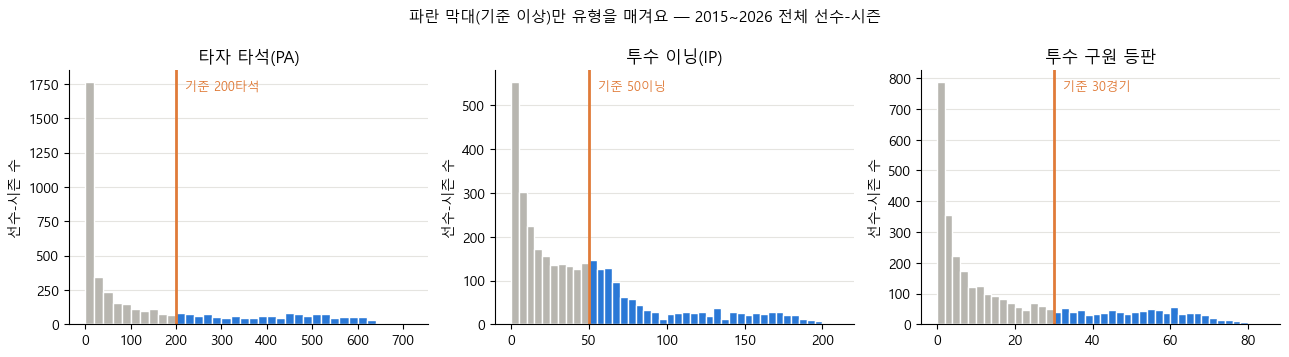

,타자 전체,타자 자격,투수 전체,투수 자격,└ 50이닝 이상,└ 구원 30경기만,쓰임
season,,,,,,,
2015,379,110,244,127,102,25,맞춤 + 배정
2016,378,112,250,130,104,26,맞춤 + 배정
2017,360,117,239,126,102,24,맞춤 + 배정
2018,331,109,260,126,95,31,맞춤 + 배정
2019,353,109,257,129,109,20,맞춤 + 배정
2020,373,108,283,140,92,48,맞춤 + 배정
2021,394,109,308,138,95,43,맞춤 + 배정
2022,356,112,281,131,96,35,맞춤 + 배정
2023,366,114,285,139,105,34,맞춤 + 배정


자격 행 합계: 타자 1,327 · 투수 1,591  (그중 2026: 타자 110 · 투수 140)


In [3]:
relief = pit["games"] - pit["starts"]                      # 구원 등판 = 등판 - 선발
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
panels = [(bat["pa"], np.arange(0, 721, 20), cluster.MIN_PA, "타자 타석(PA)", f"{cluster.MIN_PA}타석"),
          (pit["ip_outs"] / 3, np.arange(0, 211, 5), cluster.MIN_IP_OUTS / 3, "투수 이닝(IP)", f"{cluster.MIN_IP_OUTS // 3}이닝"),
          (relief, np.arange(0, 86, 2), cluster.MIN_RELIEF_APPS, "투수 구원 등판", f"{cluster.MIN_RELIEF_APPS}경기")]
for ax, (values, bins, line, title, tag) in zip(axes, panels):
    ax.hist(values, bins=bins, color=GRAY, edgecolor="white")
    ax.hist(values[values >= line], bins=bins, color=BLUE, edgecolor="white")
    ax.axvline(line, color=ORANGE, linewidth=2)
    ax.text(line, ax.get_ylim()[1] * 0.92, f"  기준 {tag}", color=ORANGE, fontsize=9)
    ax.set(title=title, ylabel="선수-시즌 수")
fig.suptitle("파란 막대(기준 이상)만 유형을 매겨요 — 2015~2026 전체 선수-시즌", fontsize=11)
plt.tight_layout()
plt.show()

qb, qp = cluster.qualify(bat, "batter"), cluster.qualify(pit, "pitcher")
by_ip = qp["ip_outs"] >= cluster.MIN_IP_OUTS
per_season = pd.DataFrame({
    "타자 전체": bat.groupby("season").size(), "타자 자격": qb.groupby("season").size(),
    "투수 전체": pit.groupby("season").size(), "투수 자격": qp.groupby("season").size(),
    "└ 50이닝 이상": qp[by_ip].groupby("season").size(), "└ 구원 30경기만": qp[~by_ip].groupby("season").size(),
})
per_season["쓰임"] = np.where(per_season.index.isin(cluster.FIT_SEASONS), "맞춤 + 배정", "배정만")
display(per_season)
print(f"자격 행 합계: 타자 {len(qb):,} · 투수 {len(qp):,}  (그중 2026: 타자 {int((qb['season'] == 2026).sum())} · 투수 {int((qp['season'] == 2026).sum())})")

**해석:** 맨 왼쪽 막대(몇 타석·몇 이닝만 뛴 선수)가 압도적으로 많아요. 1군에 잠깐 올라왔다 내려간 선수들이에요. 기준을 넘는 건 시즌마다 **타자 약 110명, 투수 약 130명**이에요(10개 구단 × 타자 11명·투수 13명 정도).
투수 중 "구원 30경기만"으로 들어온 선수가 시즌마다 20~48명이에요. 이 두 번째 기준이 없었다면 이 불펜 투수들은 유형을 받지 못했을 거예요.
2015~2025 자격 행(타자 1,217 · 투수 1,451)으로 유형을 **맞추고**, 2026 자격 행(타자 110 · 투수 140)은 **배정만** 해요.

## 4. 비율 지표 — 왜 누적 기록이 아닌 비율인가

### 왜 비율인가요?
"홈런 30개"는 **실력 × 출전 기회**예요. 600타석 선 선수와 300타석 선 선수의 홈런 수를 그대로 비교하면 "많이 뛴 선수"끼리 묶여요. 우리가 알고 싶은 건 "**어떤 스타일**의 선수인가"이니까, 기회 1번당 비율로 바꿔서 출전량의 영향을 지워요(`cluster.rates`).

### 타자 지표 6개
| 지표 | 계산 | 뜻 (높으면) |
|---|---|---|
| **K%** (삼진율) | 삼진 ÷ 타석 | 삼진을 자주 당해요. 크게 휘두르는 타자에게 흔해요 |
| **BB%** (볼넷율) | 볼넷 ÷ 타석 | 공을 잘 골라요(선구안) |
| **HR%** (홈런율) | 홈런 ÷ 타석 | 홈런을 자주 쳐요 |
| **ISO** (순장타율) | (2루타 + 2×3루타 + 3×홈런) ÷ 타수 | 안타 중 **장타**의 힘. 단타를 빼고 "한 타수당 추가로 나아간 베이스" |
| **BABIP** | (안타 − 홈런) ÷ (타수 − 삼진 − 홈런) | 공을 그라운드 안으로 쳤을 때 안타가 되는 비율. 발이 빠르거나 타구 질이 좋으면 높고, **운**도 많이 섞여요 |
| **도루율** | 도루 ÷ (단타 + 볼넷 + 몸에 맞는 공) | 1루에 나간 기회당 도루. 발 빠른 주자일수록 높아요 |

### 투수 지표 5개 (상대 타자 기준)
| 지표 | 계산 | 뜻 (높으면) |
|---|---|---|
| **K%** | 삼진 ÷ 상대 타자 | 삼진을 많이 잡아요 |
| **BB%** | (볼넷 + 몸에 맞는 공) ÷ 상대 타자 | 제구가 흔들려요 |
| **HR%** | 피홈런 ÷ 상대 타자 | 홈런을 자주 맞아요 |
| **BABIP** | (피안타 − 피홈런) ÷ (상대 타자 − 삼진 − 볼넷 − 사구 − 피홈런) | 맞은 공이 안타가 되는 비율 (수비·운 영향이 커요) |
| **선발 비중** | 선발 등판 ÷ 전체 등판 | 1이면 선발 전담, 0이면 구원 전담 |

투수에게 ISO가 없는 건, 박스스코어 투수 기록에는 피2루타·피3루타가 없어서예요.

**출력 보는 법:** 첫 표는 2015~2025 자격 행의 지표별 평균·표준편차·범위예요. 아래는 디아즈의 2025 비율 지표예요.

In [4]:
bat_r, pit_r = cluster.rates(bat, "batter"), cluster.rates(pit, "pitcher")   # 비율 지표 열을 더한 사본
qb, qp = cluster.qualify(bat_r, "batter"), cluster.qualify(pit_r, "pitcher")
fit_b, fit_p = qb[qb["season"].isin(cluster.FIT_SEASONS)], qp[qp["season"].isin(cluster.FIT_SEASONS)]

league = pd.concat({"타자": fit_b[cluster.BATTER_FEATURES].describe().T, "투수": fit_p[cluster.PITCHER_FEATURES].describe().T})
league = league[["mean", "std", "min", "50%", "max"]].rename(columns={"mean": "평균", "std": "표준편차", "min": "최소", "50%": "중앙값", "max": "최대"})
league.index = [f"{g} {FEAT_KO[f]}" for g, f in league.index]
display(league.round(3))
cols = ["season", "name", "team", "pa", "hr", "doubles", "triples", "sb", *cluster.BATTER_FEATURES]
print(f"{names_ko.get(int(hr_king['player_id']))}의 2025 비율 지표:")
display(qb[(qb["player_id"] == hr_king["player_id"]) & (qb["season"] == 2025)][cols].round(3))

,평균,표준편차,최소,중앙값,최대
타자 K%,0.179,0.058,0.051,0.174,0.440
타자 BB%,0.092,0.029,0.021,0.091,0.206
타자 HR%,0.024,0.018,0.000,0.021,0.089
타자 ISO,0.138,0.065,0.008,0.128,0.407
타자 BABIP,0.324,0.037,0.199,0.325,0.464
타자 도루율,0.061,0.068,0.000,0.038,0.547
투수 K%,0.183,0.046,0.050,0.180,0.363
투수 BB%,0.102,0.033,0.022,0.099,0.245
투수 HR%,0.022,0.010,0.000,0.021,0.069
투수 BABIP,0.300,0.035,0.185,0.299,0.430


디아즈의 2025 비율 지표:


,season,name,team,pa,hr,doubles,triples,sb,k_pct,bb_pct,hr_pct,iso,babip,sb_rate
1209,2025,Díaz,SS,617,50,32,0,1,0.162,0.097,0.081,0.33,0.304,0.006


**해석:** 자격 타자의 평균은 삼진 17.9%, 볼넷 9.2%, 홈런 2.4%(40타석에 1개), ISO .138, BABIP .324예요. 디아즈는 **HR% 8.1%(12타석에 1개)**, ISO .330으로 평균의 3배가 넘어요 — 숫자로 봐도 "홈런 타자"예요. 대신 도루율은 .006으로 거의 0이에요.
투수의 **선발 비중**은 평균 .392인데 **중앙값은 .053**이에요. 선발 전담(1에 가까움)과 구원 전담(0에 가까움)으로 둘로 갈려 있다는 뜻이고, 이 지표 하나가 투수 유형을 크게 가를 거라고 예상할 수 있어요.

### 지표끼리 얼마나 겹칠까? (상관 행렬)
두 지표가 거의 같은 정보를 담고 있으면(상관이 높으면), 유형을 나눌 때 그 방향의 정보가 **두 번** 세어져요. 그래서 지표 사이의 **상관계수**(−1 ~ +1: +1이면 함께 오르고, −1이면 반대로 움직이고, 0이면 관계 없음)를 확인해요.

**출력 보는 법:** 빨강은 함께 움직이는 쌍, 파랑은 반대로 움직이는 쌍이에요. 대각선(+1)은 자기 자신이에요.

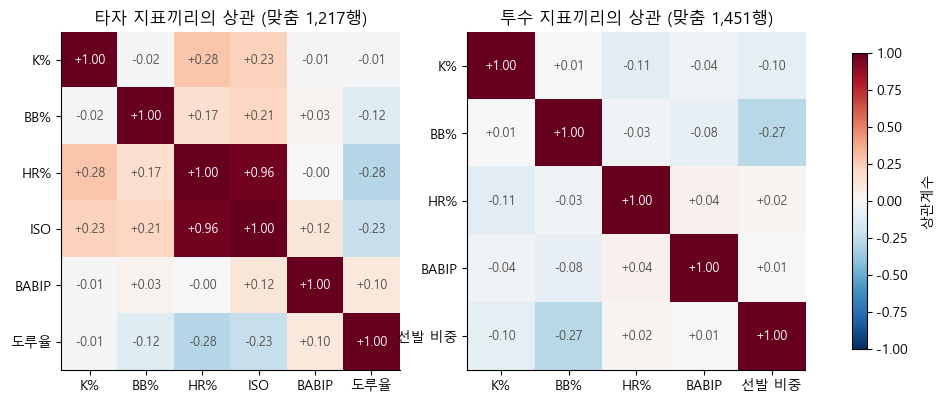

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (g, rows, feats) in zip(axes, (("batter", fit_b, cluster.BATTER_FEATURES), ("pitcher", fit_p, cluster.PITCHER_FEATURES))):
    corr = rows[feats].corr()
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(feats)), [FEAT_KO[f] for f in feats])
    ax.set_yticks(range(len(feats)), [FEAT_KO[f] for f in feats])
    ax.grid(False)
    for i in range(len(feats)):
        for j in range(len(feats)):
            ax.text(j, i, f"{corr.values[i, j]:+.2f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(corr.values[i, j]) > 0.6 else INK)
    ax.set_title(f"{GROUP_KO[g]} 지표끼리의 상관 (맞춤 {len(rows):,}행)")
fig.colorbar(im, ax=axes, shrink=0.8).set_label("상관계수", labelpad=10)
plt.show()

**해석:** 타자의 **HR%와 ISO는 +0.96**으로 거의 같은 정보예요(장타의 대부분이 홈런이니까요). 그래서 "장타력" 방향은 사실상 두 번 세어지고, 타자 유형은 장타력으로 크게 갈릴 거예요. 이건 의도한 선택이에요. ISO는 2루타·3루타 힘까지 담아 HR%와 조금 다른 정보를 주고, 사이트에서도 둘 다 보여 주기 때문이에요.
그 밖에는 대부분 |0.3| 아래로 약해요. **도루율은 장타와 반대(−0.28)**로, "발 빠른 타자는 대체로 홈런이 적다"는 상식과 같아요. 투수는 **선발 비중과 BB%가 −0.27**이에요. 선발 투수가 볼넷을 덜 주는 편이에요.

## 5. 표준화와 K 고르기

### 표준화 — 단위를 맞춰요
K%는 0.05~0.44, 도루율은 0~0.55, 선발 비중은 0~1처럼 지표마다 범위가 달라요. K-means는 **거리**로 묶기 때문에, 그대로 쓰면 범위가 큰 지표가 거리를 독차지해요.
**표준화**는 지표마다 "(값 − 평균) ÷ 표준편차"로 바꿔서 **평균 0, 표준편차 1**로 맞추는 거예요. 표준화 값 +1은 "평균보다 표준편차 1만큼 높다"(대략 상위 16%)는 뜻이에요. 평균·표준편차는 **맞춤 시즌(2015~2025) 자격 행**으로만 계산해요.

### K-means — 가장 가까운 중심으로 묶어요
**K-means**는 공간에 중심 K개를 놓고, ① 모든 선수를 가장 가까운 중심에 붙이고 ② 중심을 붙은 선수들의 평균 위치로 옮기는 일을 더 움직이지 않을 때까지 반복해요. 끝나면 선수마다 유형 번호(0~K−1)가 붙어요. 시작 위치에 따라 결과가 달라질 수 있어서 **10번 다른 시작으로 돌려 가장 촘촘한 결과**를 써요(`n_init=10`, 무작위 시드 42 고정, 1스레드 계산으로 매번 비트 단위까지 같은 결과).

### K는 몇 개가 좋을까? — 실루엣 + 유지율
K를 4·5·6·7로 모두 맞춰 보고 두 가지 점수를 더해서(`score`) 가장 큰 K를 골라요(`cluster.fit_group`).
- **실루엣**(silhouette, −1 ~ 1): 선수마다 "자기 무리와의 평균 거리 a"와 "가장 가까운 다른 무리와의 평균 거리 b"를 비교해 (b − a) ÷ max(a, b)를 내고 평균해요. 1에 가까우면 무리가 또렷이 갈리고, 0 근처면 무리 경계가 흐릿하다는 뜻이에요.
- **유지율**(retention, 0 ~ 1): 연속 두 시즌 모두 자격이 있는 선수 중 **두 해의 유형이 같은 비율**이에요. 유형이 "그 선수다움"을 잡았다면 한 해 운에 쉽게 바뀌지 않아야 해요. K가 클수록 무리가 잘게 쪼개져 유지율은 떨어지기 쉬워요.

**출력 보는 법:** 첫 표는 표준화에 쓴 평균(μ)·표준편차(σ)예요. 그다음 그룹별 K 후보 표와 그림이에요. 검은 선(score)이 가장 높은 K가 선택돼요.

fit_group 실행 시간(두 그룹): 1.0초
표준화에 쓴 평균·표준편차 (맞춤 시즌 자격 행으로 계산):


평균(μ)  표준편차(σ)
타자 K%     0.1785   0.0576
   BB%    0.0923   0.0291
   HR%    0.0242   0.0177
   ISO    0.1384   0.0647
   BABIP  0.3239   0.0375
   도루율    0.0612   0.0684
투수 K%     0.1831   0.0463
   BB%    0.1019   0.0326
   HR%    0.0220   0.0103
   BABIP  0.2995   0.0347
   선발 비중  0.3924   0.4468

타자 K 후보 비교 (선택: K=4)


,silhouette,retention,score
k,,,
4,0.1715,0.6536,0.8251
5,0.1649,0.5622,0.7271
6,0.1659,0.5431,0.7090
7,0.1666,0.4987,0.6653


투수 K 후보 비교 (선택: K=4)


,silhouette,retention,score
k,,,
4,0.2045,0.5322,0.7367
5,0.1983,0.5213,0.7196
6,0.1833,0.4544,0.6378
7,0.1836,0.4423,0.6259


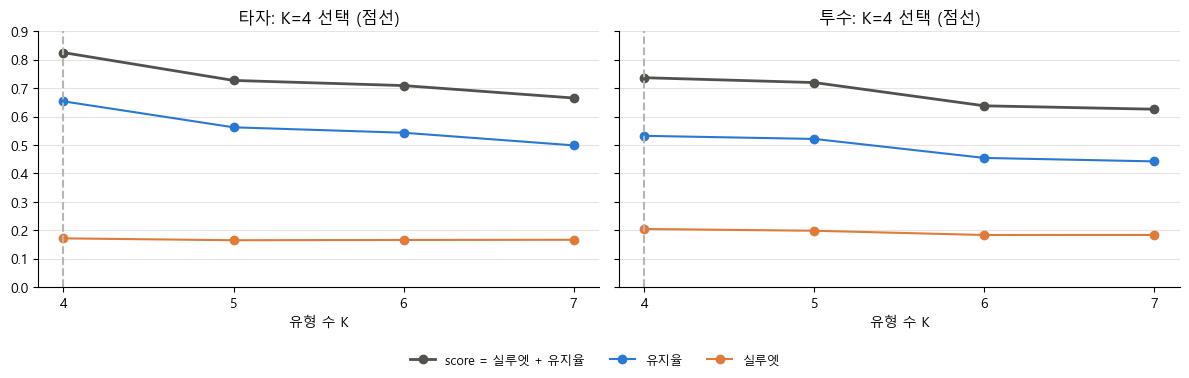

In [6]:
t = time.time()
bundles = {g: cluster.fit_group(r, g) for g, r in (("batter", bat_r), ("pitcher", pit_r))}   # 표준화 → K=4..7 → 고르기
print(f"fit_group 실행 시간(두 그룹): {time.time() - t:.1f}초")

scale = pd.concat({GROUP_KO[g]: pd.DataFrame({"평균(μ)": b["scaler"].mean_, "표준편차(σ)": b["scaler"].scale_},
                                              index=[FEAT_KO[f] for f in b["features"]]) for g, b in bundles.items()})
print("표준화에 쓴 평균·표준편차 (맞춤 시즌 자격 행으로 계산):")
display(scale.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (g, b) in zip(axes, bundles.items()):
    kt = pd.DataFrame(b["k_table"]).set_index("k")
    print(f"{GROUP_KO[g]} K 후보 비교 (선택: K={b['k']})")
    display(kt.round(4))
    ax.plot(kt.index, kt["score"], color=INK, marker="o", linewidth=2, label="score = 실루엣 + 유지율")
    ax.plot(kt.index, kt["retention"], color=BLUE, marker="o", label="유지율")
    ax.plot(kt.index, kt["silhouette"], color=ORANGE, marker="o", label="실루엣")
    ax.axvline(b["k"], color=GRAY, linestyle="--")
    ax.set(title=f"{GROUP_KO[g]}: K={b['k']} 선택 (점선)", xlabel="유형 수 K", xticks=list(kt.index), ylim=(0, 0.9))
fig.legend(*axes[0].get_legend_handles_labels(), ncol=3, fontsize=9, loc="lower center", frameon=False)
plt.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

**해석:** 두 그룹 모두 **K = 4**가 선택됐어요.
- 타자: score .825로 K = 5(.727)보다 확실히 높아요. 실루엣은 K마다 .165~.172로 거의 같고, 차이는 **유지율**(.654 vs .562)에서 나와요. 유형을 5개 이상으로 쪼개면 같은 선수가 해마다 다른 유형으로 옮겨 다니는 일이 크게 늘어요.
- 투수: K = 4(.737)와 K = 5(.720)가 가깝지만 실루엣·유지율 모두 K = 4가 높아요.

**실루엣이 .17 / .20으로 낮은 건 솔직히 짚고 갈게요.** 선수 기록은 "파워형"과 "컨택형" 사이에 칼로 자른 듯한 빈틈이 있지 않고 **연속적으로** 이어져 있어요. 그래서 어떤 K로 나눠도 경계 근처 선수가 많고 실루엣이 크게 오르지 않아요. 유형은 "자연에 존재하는 종"이라기보다 **연속된 스펙트럼을 4칸으로 나눈 요약**으로 읽는 게 정확해요(8번의 소속 확률이 경계의 정도를 보여 줘요).

## 6. 유형 프로파일과 이름

K-means의 유형 번호는 원래 아무 뜻이 없어요(돌릴 때마다 0번이 다른 무리일 수도 있어요). 그래서 `fit_group`은 번호를 **뜻 있는 순서로 다시 매겨요**: 타자는 HR%가 높은 순서(0 = 가장 장타형), 투수는 선발 비중이 높은 순서예요. 그 덕분에 다시 맞춰도 "0번 = 파워형"이 유지돼요.

그다음 `cluster.assign`으로 자격 행 **전부(2026 포함)**에 유형을 붙여요. 이름은 사람이 붙였어요. 유형마다 **중심**(그 유형 선수들의 평균 위치)을 원래 단위로 되돌려 보고, 야구 용어로 어울리는 이름과 한 줄 설명을 `config/cluster_labels.yaml`에 적었어요.

**출력 보는 법:** 행 하나가 유형 하나예요. 지표 칸은 그 유형의 "평균적인 선수"의 비율이고, 인원은 맞춤 시즌(2015~2025)과 전체(2026 포함)예요. 맨 오른쪽이 yaml의 설명이에요.

In [7]:
assigned = {}
for g, r in (("batter", bat_r), ("pitcher", pit_r)):
    a = cluster.assign(bundles[g], r)                                       # 유형·소속 확률·2D 좌표
    a["name_ko"] = [names_ko.get(int(p)) for p in a["player_id"]]           # build_from과 같은 방식으로 한글 이름
    assigned[g] = a

for g in GROUPS:
    b, a = bundles[g], assigned[g]
    prof = b["centers"].rename(columns=FEAT_KO).round(3)
    prof.insert(0, "이름", [LABELS[g][t]["name"] for t in prof.index])
    prof["인원(맞춤)"] = [int(((a["type"] == t) & a["season"].isin(b["fit_seasons"])).sum()) for t in prof.index]
    prof["인원(전체)"] = [int((a["type"] == t).sum()) for t in prof.index]
    prof["설명 (cluster_labels.yaml)"] = [LABELS[g][t]["blurb"] for t in prof.index]
    print(f"{GROUP_KO[g]} 유형 프로파일 — 중심을 원래 단위로 되돌린 값 (K={b['k']})")
    display(prof)

타자 유형 프로파일 — 중심을 원래 단위로 되돌린 값 (K=4)


,이름,K%,BB%,HR%,ISO,BABIP,도루율,인원(맞춤),인원(전체),설명 (cluster_labels.yaml)
type,,,,,,,,,,
0,파워형,0.190,0.110,0.049,0.229,0.33,0.035,274,299,"타석당 홈런 4.9%, ISO .229로 장타력이 가장 높고 볼넷(11%)도 잘 고..."
1,장타 지향형,0.221,0.078,0.026,0.138,0.32,0.035,333,368,"삼진 22%로 가장 많고 볼넷은 적지만 ISO .138로 장타를 노리는, 거칠지만 ..."
2,컨택형,0.135,0.097,0.013,0.098,0.32,0.043,421,456,"삼진 13.5%로 가장 적고 홈런은 드문, 공을 맞히는 데 강점이 있는 테이블세터·..."
3,주루형,0.184,0.081,0.012,0.098,0.33,0.186,189,204,1루 도달 기회당 도루 .186으로 압도적인 발 빠른 유형. 장타는 적다.


투수 유형 프로파일 — 중심을 원래 단위로 되돌린 값 (K=4)


,이름,K%,BB%,HR%,BABIP,선발 비중,인원(맞춤),인원(전체),설명 (cluster_labels.yaml)
type,,,,,,,,,
0,선발형,0.185,0.086,0.020,0.299,0.958,465,512,등판의 96%가 선발. 볼넷 8.6%로 제구가 안정적이고 긴 이닝을 책임지는 유형.
1,스윙맨형,0.154,0.097,0.036,0.307,0.285,279,301,선발 비중 29%로 선발과 롱릴리프를 오간다. 삼진은 적고 피홈런(3.6%)이 많은 편.
2,파워 불펜형,0.186,0.129,0.019,0.265,0.085,334,368,거의 구원 등판(선발 8.5%). 볼넷 12.9%로 제구는 흔들리지만 피BABIP ...
3,삼진 불펜형,0.200,0.101,0.017,0.326,0.043,373,410,"구원 전담(선발 4.3%)에 삼진 20%로 가장 높은, 짧은 이닝을 삼진으로 막는 ..."


**해석 (타자):**
- **0 파워형**(299명): HR% 4.9%(평균의 2배), ISO .229, 볼넷도 11%로 가장 많아요. 투수들이 피해 가는 중심 타자예요.
- **1 장타 지향형**(368명): 삼진 22.1%로 가장 많고 볼넷은 7.8%로 가장 적어요. 장타(ISO .138)는 평균 수준이에요. "크게 휘두르지만 파워형만큼 넘기진 못하는" 타자예요.
- **2 컨택형**(456명, 가장 많음): 삼진 13.5%로 가장 적고 홈런은 드물어요. 공을 맞히는 데 강점이 있는 교타자예요.
- **3 주루형**(204명): 도루율 .186으로 다른 유형(.035~.043)의 4~5배예요. 장타는 컨택형만큼 적어요.

**해석 (투수):**
- **0 선발형**(512명): 등판의 96%가 선발, 볼넷 8.6%로 가장 적어요.
- **1 스윙맨형**(301명): 선발 비중 29%로 선발과 긴 구원을 오가요. 삼진은 15.4%로 가장 적고 피홈런 3.6%로 가장 많아요.
- **2 파워 불펜형**(368명): 거의 구원(선발 8.5%), 볼넷 12.9%로 제구는 흔들리지만 피BABIP .265로 맞아도 안타가 덜 돼요.
- **3 삼진 불펜형**(410명): 구원 전담(선발 4.3%), 삼진 20%로 가장 많아요.

BABIP는 네 타자 유형이 .32~.33으로 거의 같아요. BABIP는 운이 많이 섞인 지표라 유형을 가르는 힘이 약하다는 뜻이에요.

### 표준화 공간에서 본 유형 중심
같은 중심을 **표준화 값**으로 보면 "평균보다 얼마나 튀는지"가 한눈에 보여요. K-means가 실제로 거리를 잰 공간이 바로 이 공간이에요.

**출력 보는 법:** 칸의 숫자는 "평균보다 표준편차 몇 개만큼 높은가(+) / 낮은가(−)"예요. 진한 빨강·파랑일수록 그 유형을 정의하는 특징이에요.

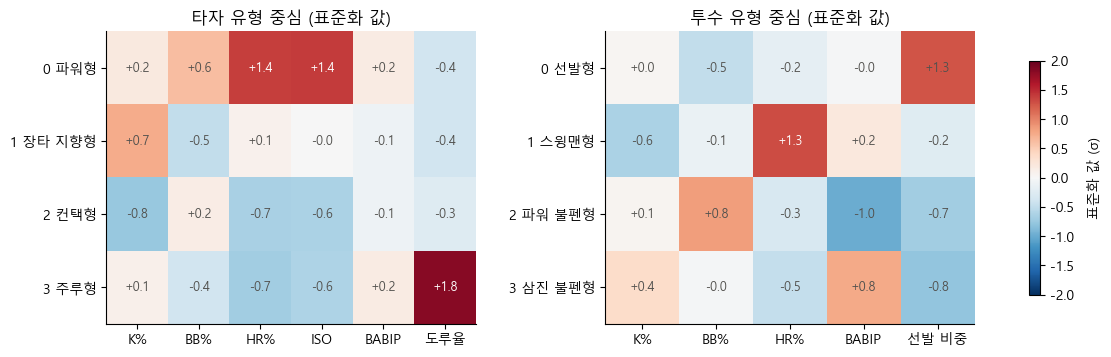

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={"wspace": 0.35})
for ax, g in zip(axes, GROUPS):
    cz = bundles[g]["centers_z"]
    im = ax.imshow(cz.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(cz.shape[1]), [FEAT_KO[f] for f in cz.columns])
    ax.set_yticks(range(cz.shape[0]), [f"{t} {LABELS[g][t]['name']}" for t in cz.index])
    ax.grid(False)
    for i in range(cz.shape[0]):
        for j in range(cz.shape[1]):
            ax.text(j, i, f"{cz.values[i, j]:+.1f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(cz.values[i, j]) > 1.3 else INK)
    ax.set_title(f"{GROUP_KO[g]} 유형 중심 (표준화 값)")
fig.colorbar(im, ax=axes, shrink=0.8).set_label("표준화 값 (σ)", labelpad=10)
plt.show()

**해석:** 유형마다 **진한 칸 한두 개**가 이름의 근거예요.
- 타자: 파워형은 HR%·ISO **+1.4**, 장타 지향형은 K% **+0.7**과 BB% −0.5, 컨택형은 K% **−0.8**, 주루형은 도루율 **+1.8**(가장 진한 칸)이에요.
- 투수: 선발형은 선발 비중 **+1.3**, 스윙맨형은 HR% **+1.3**, 파워 불펜형은 BABIP **−1.0**과 BB% +0.8, 삼진 불펜형은 BABIP +0.8과 K% +0.4예요.

솔직하게 덧붙이면, 두 불펜 유형을 가르는 가장 큰 축이 **BABIP**(운이 많이 섞인 지표)예요. 그래서 10번에서 보듯 두 불펜 유형 사이를 해마다 오가는 투수가 많아요. 이름의 "파워"·"삼진"은 각 유형의 상대적 특징을 요약한 사람의 판단이에요.

## 7. 2D 지도 (PCA)

타자는 지표 6개, 투수는 5개라서 공간이 6차원·5차원이에요. 사람 눈으로 보려면 2차원으로 줄여야 해요.
**PCA**(주성분 분석)는 데이터가 **가장 넓게 퍼진 방향**을 찾아 그 방향을 x축으로, 그것과 직각인 방향 중 두 번째로 넓게 퍼진 방향을 y축으로 삼아요. 정보를 가장 적게 잃으면서 평면에 펼치는 방법이에요. 사이트의 "유형 지도"도 이 좌표(`x`, `y`)를 써요.

**출력 보는 법:** 먼저 표에서 각 축이 어떤 지표의 조합인지(무게가 클수록 그 지표가 축을 이끌어요)와 축이 담은 정보의 비율을 봐요. 그림의 점 하나는 선수-시즌 하나(2015~2025)이고, 테두리가 진한 점은 **2025 유형별 대표**(그 유형 소속 확률이 가장 높은 선수)와 2번의 예시 선수예요.

타자 PCA — 설명하는 분산 비율: x축 37.5%, y축 18.2% (합 55.7%). 각 지표가 축에 주는 무게:


,x축(PC1),y축(PC2)
K%,0.26,0.31
BB%,0.21,-0.22
HR%,0.64,0.04
ISO,0.63,0.12
BABIP,0.04,0.70
도루율,-0.28,0.59


투수 PCA — 설명하는 분산 비율: x축 26.5%, y축 21.8% (합 48.3%). 각 지표가 축에 주는 무게:


,x축(PC1),y축(PC2)
K%,-0.31,-0.59
BB%,-0.62,0.34
HR%,0.24,0.65
BABIP,0.24,0.20
선발 비중,0.63,-0.27


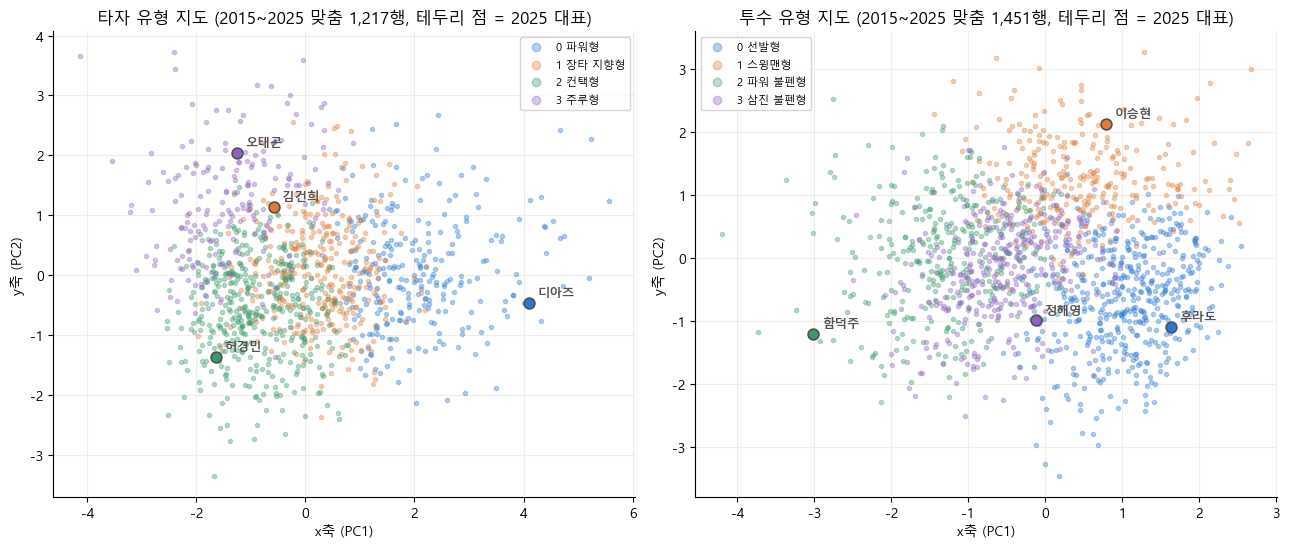

In [9]:
for g in GROUPS:
    pca = bundles[g]["pca"]
    load = pd.DataFrame(pca.components_.T, index=[FEAT_KO[f] for f in bundles[g]["features"]], columns=["x축(PC1)", "y축(PC2)"])
    print(f"{GROUP_KO[g]} PCA — 설명하는 분산 비율: x축 {pca.explained_variance_ratio_[0]:.1%}, y축 {pca.explained_variance_ratio_[1]:.1%} "
          f"(합 {pca.explained_variance_ratio_.sum():.1%}). 각 지표가 축에 주는 무게:")
    display(load.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
for ax, g in zip(axes, GROUPS):
    a = assigned[g]
    fit_rows = a[a["season"].isin(cluster.FIT_SEASONS)]
    for t in range(bundles[g]["k"]):
        rows = fit_rows[fit_rows["type"] == t]
        ax.scatter(rows["x"], rows["y"], s=9, alpha=0.35, color=TYPE_COLORS[t], label=f"{t} {LABELS[g][t]['name']}")
    picks = a[a["season"] == 2025].sort_values("prob", ascending=False).groupby("type").head(1)    # 유형별 2025 대표
    if g == "batter":
        picks = pd.concat([picks, a[(a["season"] == 2025) & (a["player_id"] == hr_king["player_id"])]])
    else:
        picks = pd.concat([picks, a[(a["season"] == 2025) & (a["player_id"] == ace["player_id"])]])
    for _, r in picks.drop_duplicates(["season", "player_id"]).iterrows():
        ax.scatter(r["x"], r["y"], s=60, color=TYPE_COLORS[int(r["type"])], edgecolor=INK, linewidth=1.2, zorder=3)
        ax.annotate(f"{r['name_ko'] or r['name']}", (r["x"], r["y"]), xytext=(6, 5), textcoords="offset points",
                    fontsize=9, color=INK, fontweight="bold")
    ax.set(title=f"{GROUP_KO[g]} 유형 지도 (2015~2025 맞춤 {len(fit_rows):,}행, 테두리 점 = 2025 대표)", xlabel="x축 (PC1)", ylabel="y축 (PC2)")
    ax.grid(True, axis="both", color="#eeede9")
    ax.legend(fontsize=8, loc="best", markerscale=2)
plt.tight_layout()
plt.show()

**해석:**
- **타자 x축(37.5%)**은 HR%·ISO의 무게가 0.6대로 사실상 **"장타력 축"**이에요. 오른쪽으로 갈수록 홈런 타자라서, 파워형(파랑)이 오른쪽에 있고 디아즈가 맨 오른쪽 근처에 있어요. **y축(18.2%)**은 BABIP·도루율이 이끄는 **"발·인플레이 타구 축"**이라 주루형(보라, 오태곤)이 위쪽에 모여요. 컨택형(초록, 허경민)은 왼쪽 아래(장타도 삼진도 적음)예요.
- **투수 x축(26.5%)**은 선발 비중(+0.63)과 BB%(−0.62): 오른쪽일수록 **선발이고 제구가 좋은** 투수라 선발형(후라도)이 오른쪽이에요. **y축(21.8%)**은 HR%(+0.65)와 K%(−0.59): 위로 갈수록 **삼진은 적고 홈런을 많이 맞는** 투수라 스윙맨형(이승현)이 위쪽이에요.
- 두 축이 담은 정보는 타자 56%, 투수 48%뿐이에요. 그래서 지도에서는 유형이 꽤 겹쳐 보이지만, 실제 6·5차원 공간에서는 지도보다 더 잘 갈려 있어요. **지도는 "대략 어디쯤"을 보여 주는 그림**이고, 유형은 2D 좌표가 아니라 원래 공간의 거리로 정해요.

## 8. 소속 확률 — 얼마나 확실하게 그 유형인가

K-means는 "가장 가까운 중심" 하나만 알려 줘요. 하지만 컨택형과 주루형의 딱 중간에 있는 선수도 있어요. 그래서 선수마다 **유형별 소속 확률**(합 = 1)을 함께 내고, 자기 유형의 확률을 `prob`이라고 불러요.

### 어떻게 계산하나요? — `kmeans_softmax`
표준화 공간에서 각 유형 중심까지의 거리 d로, **가까운 중심일수록 큰 몫**을 줘요.

  소속 확률(t) ∝ exp(−d_t² ÷ (2·s²))

s²는 "선수들이 자기 중심에서 보통 얼마나 떨어져 있나"(지표 하나당 분산, 타자 .59 · 투수 .61)예요. 가장 가까운 중심이 항상 가장 큰 확률을 받으니까 **"화면에 보이는 유형 = 소속 확률이 가장 큰 유형"**이 구조적으로 언제나 성립해요.
주의할 점: 이 확률은 거리로 만든 **상대적 확신도**예요. "80%인 선수 100명 중 80명이 정말 그 유형"처럼 실제 빈도에 맞춰 보정(캘리브레이션)된 확률은 아니에요(정답이 없는 문제라 보정할 기준도 없어요).

**출력 보는 법:** 그림은 전체 자격 행의 `prob` 분포를 유형 색으로 쌓은 거예요. 오른쪽(100%)에 몰릴수록 유형이 또렷한 선수가 많아요.

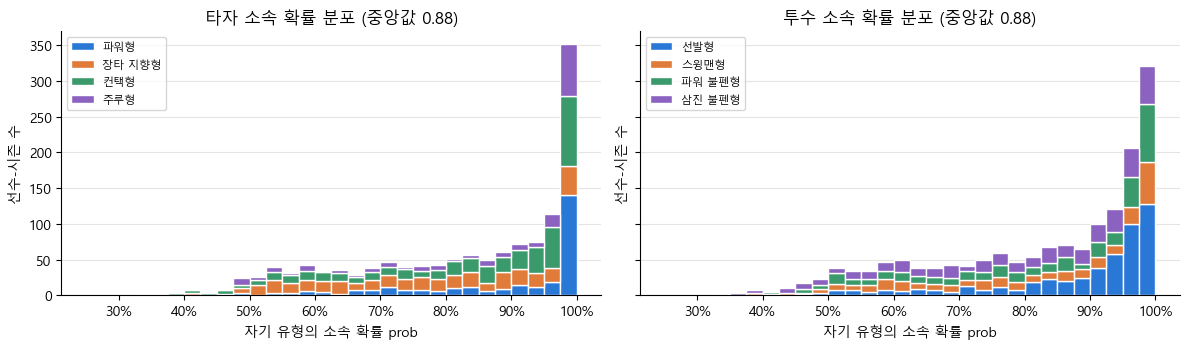

타자: prob 0.9 이상 46.2% · 0.6 미만(경계) 14.5% · 최댓값 성분 = 유형인 행 100.0%
투수: prob 0.9 이상 47.0% · 0.6 미만(경계) 14.0% · 최댓값 성분 = 유형인 행 100.0%


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
for ax, g in zip(axes, GROUPS):
    a = assigned[g]
    ax.hist([a.loc[a["type"] == t, "prob"] for t in range(bundles[g]["k"])], bins=np.linspace(0.25, 1, 31), stacked=True,
            color=TYPE_COLORS[:bundles[g]["k"]], label=[LABELS[g][t]["name"] for t in range(bundles[g]["k"])], edgecolor="white")
    ax.set(title=f"{GROUP_KO[g]} 소속 확률 분포 (중앙값 {a['prob'].median():.2f})", xlabel="자기 유형의 소속 확률 prob", ylabel="선수-시즌 수")
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

for g in GROUPS:
    a = assigned[g]
    print(f"{GROUP_KO[g]}: prob 0.9 이상 {np.mean(a['prob'] >= 0.9):.1%} · 0.6 미만(경계) {np.mean(a['prob'] < 0.6):.1%} "
          f"· 최댓값 성분 = 유형인 행 {cluster.gmm_agreement(a):.1%}")

**해석:** `prob` 중앙값은 두 그룹 모두 **.88**이에요. 절반쯤(46~47%)은 0.9 이상으로 유형이 또렷하고, **약 14%는 0.6 미만**으로 두 유형 사이 경계에 있어요. 5번의 낮은 실루엣과 같은 이야기예요: 경계에 있는 선수가 적지 않아요.
마지막 줄의 "최댓값 성분 = 유형인 행 100%"는 위에서 말한 구조적 성질을 실제 데이터로 확인한 거예요.

### 경계에 있는 선수, 그리고 왜 GMM을 쓰지 않았나
아래 표는 2025 선수 중 `prob`이 가장 낮은 5명과, 두 번째로 가까운 유형이에요.

그다음 표는 **GMM**과의 비교예요. **GMM**(가우시안 혼합 모델)은 유형마다 "종 모양 구름"을 가정하고, 그 구름들로 데이터를 가장 잘 설명하도록 맞춘 뒤 "이 선수가 각 구름에서 나왔을 확률"을 내요. 확률 모델이라서 처음에는 소속 확률을 GMM으로 내려고 했어요. 구름 모양 가정(공분산)을 세 가지(tied·diag·full)로 맞추고, **"GMM이 가장 높은 확률을 주는 유형 = K-means 유형"인 비율(일치도)**을 쟀어요. 기준은 95% 이상이었어요.

**출력 보는 법:** 첫 두 표에서 `prob`과 `두 번째 확률`이 가까울수록 경계에 있어요. 마지막 표의 일치도가 1에 가까워야 GMM을 쓸 수 있어요.

In [11]:
for g in GROUPS:
    a = assigned[g][assigned[g]["season"] == 2025].copy()
    mem = np.array(a["membership"].tolist())
    second = np.argsort(-mem, axis=1)[:, 1]                                 # 두 번째로 가까운 유형
    a["유형"] = [LABELS[g][t]["name"] for t in a["type"]]
    a["두 번째 유형"] = [LABELS[g][t]["name"] for t in second]
    a["두 번째 확률"] = mem[np.arange(len(a)), second]
    a["team"] = a["team"].map(TEAM_KO)
    cols = ["name_ko", "team", "유형", "prob", "두 번째 유형", "두 번째 확률", *bundles[g]["features"]]
    print(f"2025 {GROUP_KO[g]} 중 소속 확률이 가장 낮은 5명 — 두 유형 사이 경계에 있는 선수")
    display(a.sort_values("prob")[cols].head(5).rename(columns={"name_ko": "이름", "team": "팀", **FEAT_KO}).round(3))

gmm = pd.DataFrame({GROUP_KO[g]: {**{f"GMM {c} 일치도": v for c, v in b["gmm_candidates"].items()},
                                   "선택된 방식": b["membership_method"], "s² (차원당 분산)": round(b["softmax_s2"], 4)}
                    for g, b in bundles.items()})
print("GMM 후보 3개의 맞춤 행 일치도 (가장 높은 소속 확률 성분 = K-means 유형인 비율)와 선택된 방식")
display(gmm)

2025 타자 중 소속 확률이 가장 낮은 5명 — 두 유형 사이 경계에 있는 선수


,이름,팀,유형,prob,두 번째 유형,두 번째 확률,K%,BB%,HR%,ISO,BABIP,도루율
1200,문현빈,한화,컨택형,0.411,주루형,0.356,0.142,0.066,0.021,0.133,0.359,0.099
1182,손호영,롯데,컨택형,0.456,장타 지향형,0.379,0.183,0.061,0.011,0.073,0.306,0.071
1117,강민호,삼성,장타 지향형,0.488,컨택형,0.481,0.151,0.083,0.026,0.148,0.298,0.017
1150,김호령,KIA,주루형,0.491,장타 지향형,0.481,0.253,0.091,0.016,0.151,0.379,0.121
1160,김규성,KIA,장타 지향형,0.500,컨택형,0.320,0.227,0.097,0.014,0.067,0.298,0.082


2025 투수 중 소속 확률이 가장 낮은 5명 — 두 유형 사이 경계에 있는 선수


,이름,팀,유형,prob,두 번째 유형,두 번째 확률,K%,BB%,HR%,BABIP,선발 비중
1420,황준서,한화,선발형,0.343,삼진 불펜형,0.255,0.228,0.112,0.028,0.297,0.522
1428,손주환,NC,삼진 불펜형,0.385,파워 불펜형,0.293,0.162,0.088,0.022,0.289,0.000
1366,최민준,SSG,삼진 불펜형,0.404,스윙맨형,0.321,0.149,0.091,0.020,0.301,0.200
1350,주권,KT,삼진 불펜형,0.455,스윙맨형,0.404,0.104,0.071,0.016,0.304,0.000
1353,전상현,KIA,파워 불펜형,0.496,삼진 불펜형,0.404,0.169,0.074,0.014,0.273,0.000


GMM 후보 3개의 맞춤 행 일치도 (가장 높은 소속 확률 성분 = K-means 유형인 비율)와 선택된 방식


,타자,투수
GMM tied 일치도,0.843057,0.749828
GMM diag 일치도,0.526705,0.508615
GMM full 일치도,0.580937,0.507926
선택된 방식,kmeans_softmax,kmeans_softmax
s² (차원당 분산),0.5913,0.6111


**해석:**
- **문현빈**(한화)은 컨택형 .41 vs 주루형 .36이에요. 삼진이 적고(14.2%) 도루율(.099)도 평균보다 높아 두 유형의 특징을 반씩 가졌어요. **강민호**(삼성)는 장타 지향형 .488 vs 컨택형 .481로 거의 반반이에요.
- 투수 **황준서**(한화)는 선발 비중 .52(등판의 절반이 선발)라 선발형·불펜형 어느 쪽에도 딱 맞지 않아 `prob`이 .34밖에 안 돼요.
- **GMM 일치도는 가장 좋은 tied도 타자 84%, 투수 75%**였어요. GMM을 썼다면 타자 6명 중 1명, 투수 4명 중 1명은 화면에 "파워형"이라고 나오는데 소속 확률은 다른 유형이 가장 높은, **서로 모순된 정보**를 보게 돼요. 기준(95%)에 크게 못 미쳐서 GMM 대신 `kmeans_softmax`를 골랐어요.

"더 그럴듯한 확률 모델"보다 **"유형과 확률이 언제나 같은 말을 하는 것"**을 택한 거예요. 대신 이 확률은 보정된 확률이 아니라는 점을 성적표(`cluster_quality.membership_note`)와 사이트에 함께 적어 뒀어요.

## 9. 비슷한 선수

사이트의 선수 화면에는 "이 선수와 가장 비슷한 선수-시즌 5개"가 나와요(`cluster.similar_players`).
비슷함은 표준화 공간의 **코사인 유사도**로 재요. 두 선수를 원점(리그 평균)에서 뻗은 화살표로 보고, **두 화살표가 가리키는 방향이 얼마나 같은지**(같으면 1, 직각이면 0, 반대면 −1)를 재는 거예요. "평균보다 홈런 많고, 삼진 조금 적고, 발은 느린" 식의 **스타일의 모양**이 같으면 높고, 얼마나 극단적인지(화살표 길이)는 덜 따져요. 같은 선수의 다른 시즌은 빼요.

**출력 보는 법:** 첫 줄(기준)이 2025 홈런 1위 **디아즈**, 두 번째 표는 2025 선발형 중 이닝 1위 **후라도**예요. 아래 5줄이 유사도 순서예요. 한글 이름을 찾지 못한 선수는 로마자로 나와요. 팀은 지금 구단명으로 적었어요(예: 2017년 SK도 SSG).

In [12]:
similar = {g: cluster.similar_players(bundles[g], assigned[g]) for g in GROUPS}   # 표준화 공간 코사인 유사도 상위 5
starter = assigned["pitcher"][(assigned["pitcher"]["season"] == 2025) & (assigned["pitcher"]["type"] == 0)]
starter = starter.sort_values("ip_outs", ascending=False).iloc[0]                 # 2025 선발형 중 이닝 1위
for g, key in (("batter", (2025, int(hr_king["player_id"]))), ("pitcher", (2025, int(starter["player_id"])))):
    a = assigned[g].set_index(["season", "player_id"])
    me = a.loc[key]
    feats = bundles[g]["features"]
    rows = [{"순위": "기준", "시즌": key[0], "이름": me["name_ko"] or me["name"], "팀": TEAM_KO[me["team"]],
             "유형": LABELS[g][int(me["type"])]["name"], "유사도": np.nan, **{FEAT_KO[f]: me[f] for f in feats}}]
    for i, s in enumerate(similar[g][key], start=1):
        o = a.loc[(s["season"], s["player_id"])]
        rows.append({"순위": i, "시즌": s["season"], "이름": o["name_ko"] or o["name"], "팀": TEAM_KO[o["team"]],
                     "유형": LABELS[g][int(o["type"])]["name"], "유사도": s["similarity"], **{FEAT_KO[f]: o[f] for f in feats}})
    print(f"{me['name_ko']}({key[0]})와 가장 비슷한 {GROUP_KO[g]}-시즌 5개")
    display(pd.DataFrame(rows).set_index("순위").round(3))

디아즈(2025)와 가장 비슷한 타자-시즌 5개


,시즌,이름,팀,유형,유사도,K%,BB%,HR%,ISO,BABIP,도루율
순위,,,,,,,,,,,
기준,2025,디아즈,삼성,파워형,NaN,0.162,0.097,0.081,0.330,0.304,0.006
1,2017,오재일,두산,파워형,0.982,0.173,0.097,0.056,0.255,0.327,0.008
2,2017,Han Yoo-seom,SSG,파워형,0.981,0.192,0.112,0.071,0.320,0.306,0.018
3,2023,최정,SSG,파워형,0.975,0.160,0.108,0.053,0.251,0.313,0.045
4,2024,최정,SSG,파워형,0.972,0.210,0.101,0.068,0.303,0.312,0.034
5,2018,Han Yoo-seom,SSG,파워형,0.964,0.224,0.094,0.074,0.317,0.302,0.030


후라도(2025)와 가장 비슷한 투수-시즌 5개


,시즌,이름,팀,유형,유사도,K%,BB%,HR%,BABIP,선발 비중
순위,,,,,,,,,,
기준,2025,후라도,삼성,선발형,NaN,0.176,0.049,0.021,0.262,1.0
1,2023,태너,NC,선발형,0.997,0.177,0.053,0.023,0.261,1.0
2,2020,켈리,LG,선발형,0.973,0.183,0.070,0.022,0.272,1.0
3,2024,원태인,삼성,선발형,0.950,0.176,0.072,0.025,0.270,1.0
4,2025,원태인,삼성,선발형,0.941,0.156,0.048,0.029,0.260,1.0
5,2021,요키시,키움,선발형,0.940,0.171,0.065,0.016,0.278,1.0


**해석:**
- 디아즈와 가장 비슷한 타자-시즌은 **오재일(2017)**, **한유섬(2017·2018, 로마자 Han Yoo-seom)**, **최정(2023·2024)**이에요. 모두 리그를 대표하는 홈런 타자이고 모두 파워형이에요. 유사도 .96~.98은 "방향이 거의 같다"는 뜻이지만, 디아즈의 HR%(8.1%)는 이들(5.3~7.4%)보다 더 커요. 코사인 유사도가 **극단의 정도보다 모양**을 본다는 걸 보여 주는 예예요.
- 후라도와 가장 비슷한 투수는 **태너(2023, .997)**, 켈리(2020), 원태인(2024·2025), 요키시(2021)예요. 모두 선발 전담에 볼넷이 적은(4.8~7.2%) 제구형 선발이에요. 원태인은 2024·2025 두 시즌이 모두 들어왔어요(빼는 건 기준 선수 자신의 다른 시즌뿐이에요).

## 10. 해마다 유형이 유지되나 — 전이 행렬

유형이 "그 선수다움"을 잡았다면, 같은 선수는 다음 해에도 대체로 같은 유형이어야 해요. **전이 행렬**은 "2024년에 A 유형이던 선수가 2025년에 어느 유형이 됐나"를 표로 그린 거예요. 두 해 모두 자격이 있는 선수만 세요.

**출력 보는 법:** 행(세로)이 2024 유형, 열(가로)이 2025 유형이에요. 행마다 합이 100%이고, **대각선이 진할수록** 유형이 잘 유지돼요. 아래 표는 모든 시즌 쌍의 유지율이에요.

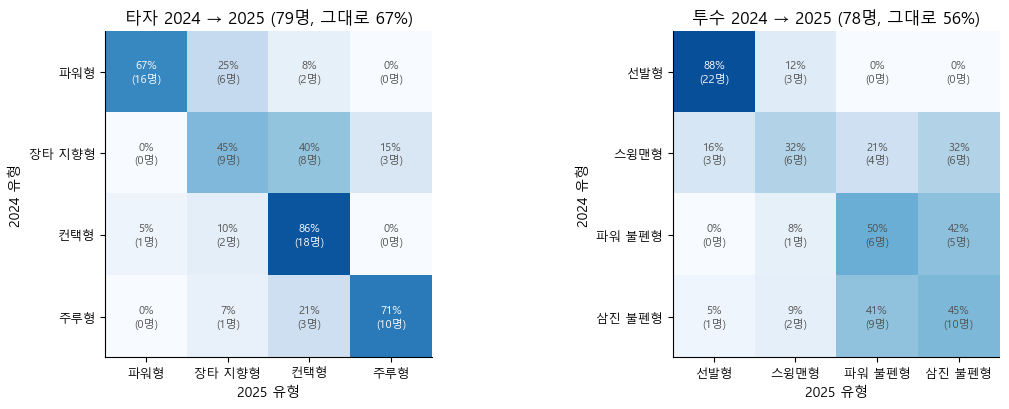

시즌 쌍별 유지율 (두 시즌 모두 자격이 있는 선수 중 유형이 같은 비율)


,2015→2016,2016→2017,2017→2018,2018→2019,2019→2020,2020→2021,2021→2022,2022→2023,2023→2024,2024→2025,2025→2026,전체(2015~2026)
타자,0.65,0.69,0.62,0.58,0.68,0.68,0.77,0.65,0.55,0.67,0.68,0.66
투수,0.51,0.54,0.49,0.42,0.53,0.55,0.52,0.61,0.55,0.56,0.55,0.53


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, g in zip(axes, GROUPS):
    a = assigned[g]
    pair = a[a["season"] == 2024][["player_id", "type"]].merge(a[a["season"] == 2025][["player_id", "type"]],
                                                                on="player_id", suffixes=("_2024", "_2025"))
    counts = pd.crosstab(pair["type_2024"], pair["type_2025"]).reindex(index=range(4), columns=range(4), fill_value=0)
    share = counts.div(counts.sum(axis=1), axis=0)
    ax.imshow(share.values, cmap="Blues", vmin=0, vmax=1)
    names = [LABELS[g][t]["name"] for t in range(4)]
    ax.set_xticks(range(4), names, fontsize=9)
    ax.set_yticks(range(4), names, fontsize=9)
    ax.grid(False)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f"{share.values[i, j]:.0%}\n({counts.values[i, j]}명)", ha="center", va="center", fontsize=8,
                    color="white" if share.values[i, j] > 0.5 else INK)
    ax.set(title=f"{GROUP_KO[g]} 2024 → 2025 ({len(pair)}명, 그대로 {np.mean(pair['type_2024'] == pair['type_2025']):.0%})",
           xlabel="2025 유형", ylabel="2024 유형")
plt.tight_layout()
plt.show()

ret = pd.DataFrame({GROUP_KO[g]: {f"{s}→{s + 1}": cluster.retention(assigned[g][assigned[g]["season"].isin([s, s + 1])])
                                  for s in SEASONS[:-1]} for g in GROUPS})
ret.loc["전체(2015~2026)"] = [cluster.retention(assigned[g]) for g in GROUPS]
print("시즌 쌍별 유지율 (두 시즌 모두 자격이 있는 선수 중 유형이 같은 비율)")
display(ret.T.round(2))

**해석:**
- 타자(79명): **컨택형 86%**, 주루형 71%, 파워형 67%가 그대로였어요. 가장 잘 바뀌는 건 **장타 지향형(45%)**인데, 40%가 컨택형으로 옮겼어요. 삼진이 줄면 바로 컨택형 쪽으로 넘어가는, 두 유형 사이 경계가 가까운 유형이에요.
- 투수(78명): **선발형 88%**는 매우 안정적이에요(선발 비중은 역할이라 잘 안 바뀌니까요). 반면 **파워 불펜형 ↔ 삼진 불펜형**은 서로 40% 넘게 오가요(다만 각각 12명·22명이라 표본이 작아요). 6번에서 본 것처럼 두 불펜 유형을 가르는 축이 해마다 출렁이는 BABIP라서예요. 스윙맨형도 32%만 유지돼요(역할이 해마다 바뀌는 투수들).
- 전체 유지율은 **타자 66%, 투수 53%**예요. 4개 중 하나를 아무렇게나 고르면 같을 확률이 25% 정도이니 우연보다 훨씬 높지만, 특히 불펜 투수의 유형은 "올해의 스타일"로 읽는 게 맞아요.

## 11. 2026 팀 로스터 구성

사이트의 팀 화면은 팀마다 **타선이 어떤 유형으로 이뤄졌는지**를 보여 줘요(`data/public/teams.json`의 `roster_types`). 그 시즌 그 팀의 자격 타자(200타석 이상)의 **타석을 유형별로 더해** 비중을 낸 값이에요(많이 뛴 선수일수록 무게가 커요).
2026은 시즌이 끝난 뒤의 기록으로 유형을 매긴 값이라, "시즌을 돌아보는 요약"이에요(예측에 쓰는 값이 아니에요).

**출력 보는 법:** 막대 하나가 팀 하나(위에서부터 2026 승수 순)이고, 색이 유형이에요. 아래 표가 같은 숫자예요.

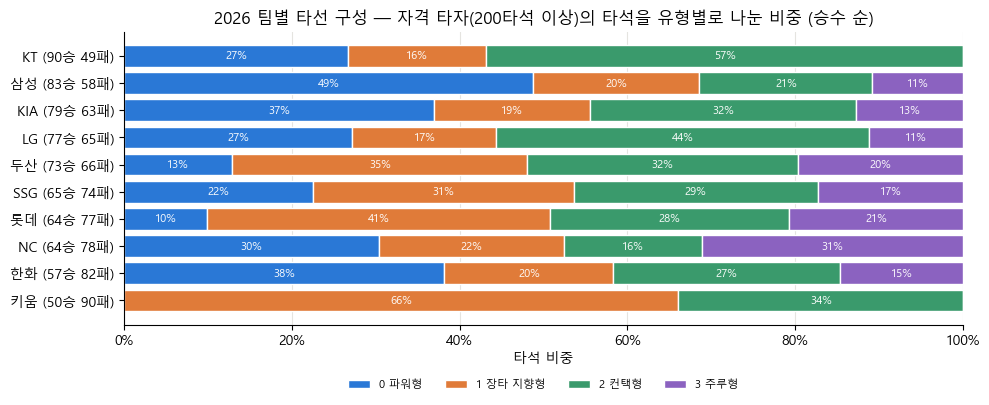

,승,패,파워형,장타 지향형,컨택형,주루형
팀,,,,,,
KT,90,49,0.267,0.165,0.568,0.000
삼성,83,58,0.488,0.198,0.206,0.108
KIA,79,63,0.369,0.187,0.317,0.127
LG,77,65,0.272,0.172,0.444,0.112
두산,73,66,0.129,0.352,0.322,0.197
SSG,65,74,0.225,0.311,0.291,0.173
롯데,64,77,0.099,0.409,0.285,0.207
NC,64,78,0.304,0.220,0.165,0.311
한화,57,82,0.382,0.201,0.270,0.147


In [14]:
teams_json = json.loads((ROOT / "data" / "public" / "teams.json").read_text(encoding="utf-8"))
t26 = pd.DataFrame([{"팀": tm["name"], "승": tm["wins"], "패": tm["losses"],
                     **{t: tm["roster_types"]["batter"].get(str(t), 0.0) for t in range(4)}}
                    for tm in teams_json["teams"] if tm["season"] == 2026]).sort_values("승", ascending=False)
fig, ax = plt.subplots(figsize=(10, 4.2))
left = np.zeros(len(t26))
labels_y = [f"{r['팀']} ({r['승']}승 {r['패']}패)" for _, r in t26.iterrows()]
for t in range(4):
    ax.barh(labels_y, t26[t], left=left, color=TYPE_COLORS[t], label=f"{t} {LABELS['batter'][t]['name']}", edgecolor="white")
    for y, (l, v) in enumerate(zip(left, t26[t])):
        if v >= 0.08:
            ax.text(l + v / 2, y, f"{v:.0%}", ha="center", va="center", fontsize=8, color="white")
    left += t26[t].to_numpy()
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(True, axis="x", color="#e5e4e0")
ax.grid(False, axis="y")
ax.set(title="2026 팀별 타선 구성 — 자격 타자(200타석 이상)의 타석을 유형별로 나눈 비중 (승수 순)", xlabel="타석 비중")
ax.legend(ncol=4, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.tight_layout()
plt.show()
display(t26.rename(columns={t: LABELS["batter"][t]["name"] for t in range(4)}).set_index("팀").round(3))

**해석:**
- 1위 **KT**는 타선의 **57%가 컨택형**이고 주루형 자격 타자가 없어요. **삼성**은 **파워형이 49%**로 가장 많아요(디아즈가 이끄는 홈런 타선). 우승 경쟁 팀도 이렇게 색이 전혀 달라요.
- 최하위 **키움**은 파워형 자격 타자가 한 명도 없고 **장타 지향형이 66%**예요. **롯데**도 파워형이 10%뿐이에요. 반대로 **NC**는 주루형이 31%로 가장 많아요.
- 다만 이건 "어떤 유형이 많으면 이긴다"는 뜻이 **아니에요**. 10개 팀뿐이라 비교가 어렵고, 승패는 투수·수비·운이 함께 정해요. 그리고 200타석 미만 선수는 빠져 있어서 실제 라인업 전체와는 달라요. 0%인 칸은 "그 유형의 **자격** 타자가 없다"는 뜻이지, 그런 스타일의 타자가 아예 없었다는 뜻은 아니에요. 이 질문을 제대로 따져 보는 게 다음 12번이에요.

## 12. 상성 피처를 넣으면 승패 예측이 나아질까?

### 무엇을 해 봤나요?
유형으로 경기마다 **상성 피처 9개**를 만들어 03번의 승패 모델에 더해 봤어요(`features.build_dataset(types=...)`).
- `bat_type0~3_diff`: 두 팀 타선의 유형 비중 차이(홈 − 원정). 그 시즌 그날까지의 팀 타석을 유형별로 나눠요.
- `starter_type0~3_diff`: 두 선발 투수의 유형 차이(같은 유형이면 0).
- `types_known`: 양 팀 타석의 절반 이상이 유형 있는 타자이고 양 선발 모두 유형이 있으면 1.

**누수를 막는 규칙:** 경기에는 **직전 시즌 유형**만 써요. 2026 경기라면 2025 시즌 기록으로 매긴 유형이에요. 그 시즌 유형은 시즌이 끝나야 정해지니까, 쓰면 미래를 엿보는 셈이에요.
비교는 03번과 같은 방법으로 해요. 선택된 모델(로지스틱 회귀 + Platt)·캘리브레이션·설정을 **그대로 두고 피처만** 더해서, 2025(검증)와 2026(시험) 성적을 비교했어요. 결과는 `model_report.json`의 `matchup_feature_ablation`에 있어요.

**출력 보는 법:** 정확도는 높을수록, log loss·Brier는 낮을수록 좋아요. **McNemar p**는 "두 모델이 맞히고 틀린 경기의 차이가 우연으로 설명되는 정도"예요(작을수록 차이가 진짜, 보통 0.05 미만이면 유의).

In [15]:
ab = committed["matchup_feature_ablation"]
tbl = pd.DataFrame([{"구간": f"{'검증 2025' if part == 'val' else '시험 2026'}", "피처": "기존 26개" if side == "without" else "+ 상성 9개",
                     "정확도": ab[side][part]["accuracy"], "log loss": ab[side][part]["log_loss"], "Brier": ab[side][part]["brier"], "경기 수": ab[side][part]["n"]}
                    for part in ("val", "test") for side in ("without", "with")]).set_index(["구간", "피처"])
display(tbl.round(4))
print(f"추가한 피처: {ab['features_added']}")
print(f"McNemar p (시험 2026, 전 vs 후): {ab['mcnemar_p_test']:.3f} · 채택(adopt): {ab['adopt']}")
print(f"검증 범위: {ab['validation_scope']}")

정확도  log loss   Brier  경기 수
구간      피처                                     
검증 2025 기존 26개   0.5731    0.6771  0.2421   698
        + 상성 9개  0.5688    0.6778  0.2424   698
시험 2026 기존 26개   0.5940    0.6712  0.2393   702
        + 상성 9개  0.5912    0.6713  0.2393   702

추가한 피처: ['bat_type0_diff', 'bat_type1_diff', 'bat_type2_diff', 'bat_type3_diff', 'starter_type0_diff', 'starter_type1_diff', 'starter_type2_diff', 'starter_type3_diff', 'types_known']
McNemar p (시험 2026, 전 vs 후): 0.845 · 채택(adopt): False
검증 범위: 검증(2025) 비교의 직전 시즌(2024) 유형은 2025 성적까지 본 2015~2025 맞춤 중심으로 매겨져 엄밀한 시간 외(out-of-time) 비교가 아닌 전이적(transductive) 비교이고, test(2026) 비교만 엄밀한 시간 외 비교다.


**해석: 나아지지 않았어요.** 상성 피처를 더하면 검증(2025) 정확도 57.3% → 56.9%, 시험(2026) 59.4% → 59.1%로 오히려 조금 낮아지고, log loss·Brier도 소수점 넷째 자리에서 같거나 조금 나빠요. McNemar p = **0.845**로 차이는 순전히 우연 수준이에요. 그래서 **채택하지 않았어요**(`adopt: false`). 사이트의 라이브 예측도 기존 26개 피처 그대로예요.

**검증 범위도 솔직히 적어 둘게요:** 유형의 중심은 2015~2025 성적으로 맞췄어요. 그래서 2025 검증 경기에 쓴 "2024 유형"은 2025 성적까지 본 중심으로 매겨진 값이라, 엄밀한 의미의 "미래를 모르는" 비교는 아니에요(전이적 비교). **2026 시험만** 중심이 한 번도 보지 않은 시즌이라 엄밀한 시간 외 비교예요. 그 2026에서도 나아지지 않았어요.

### 왜 도움이 안 됐을까? — 유형 정보가 있는 경기가 적어요
가장 큰 이유는 **커버리지**(유형 정보가 실제로 채워진 경기의 비율)예요. 직전 시즌에 자격(200타석·50이닝·구원 30경기)을 채운 선수만 유형이 있으니까, 신인·첫해 외국인 선수·부상에서 돌아온 선수·작년에 덜 뛴 선수는 유형이 없어요.

이 셀은 이 노트북이 방금 매긴 유형으로 상성 피처를 **직접 다시 만들고**, 그 결과의 지문(SHA256)이 성적표를 만들 때 쓴 상성 표의 지문(`manifest`의 `matchup_sha256`)과 같은지도 확인해요. 같다면 위 비교 결과가 바로 이 유형으로 만든 것이라는 증거예요.

**출력 보는 법:** 막대는 시즌마다 `types_known = 1`인 경기의 비율이에요(주황 = 2026 시험 시즌). 아래 두 줄은 2026에 유형 정보가 왜 부족했는지 보여 줘요.

상성 피처 계산 3.5초 · 8,465경기
이 노트북의 유형으로 만든 상성 표 지문 = 성적표가 쓴 지문(manifest report.matchup_sha256)?: True


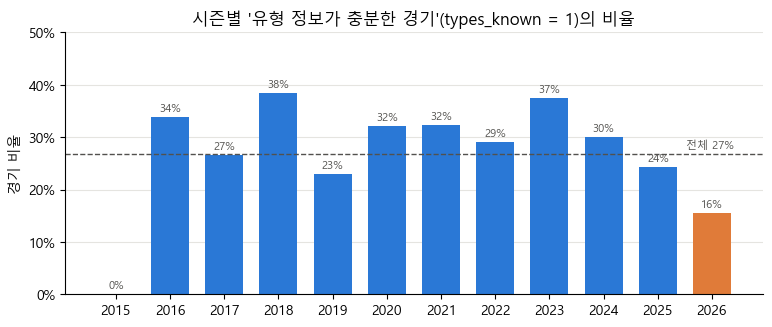

2026 선발 등판 중 '2025 유형이 있는' 투수가 던진 비율: 49.7% (선발 투수 118명 중 46명)
2026 타석 중 '2025 유형이 있는' 타자의 타석 비율: 63.8%


In [16]:
obj = {"version": cluster.CLUSTER_VERSION, "fit_seasons": bundles["batter"]["fit_seasons"], "names_ko": names_ko,
       **{g: {"bundle": bundles[g], "assigned": assigned[g], "similar": similar[g]} for g in GROUPS}}   # build_from과 같은 모양
t = time.time()
kb, kp = bundles["batter"]["k"], bundles["pitcher"]["k"]
games = features.build_dataset(SEASONS, types=cluster.types_map(obj), kb=kb, kp=kp)   # 경기마다 '직전 시즌' 유형으로 상성 피처
names = features.matchup_feature_names(kb, kp)
with tempfile.TemporaryDirectory() as tmp:
    features.save_features(games[["game_id", *names]], Path(tmp) / "matchup.parquet")
    matchup_sha = features.features_sha256(Path(tmp) / "matchup.parquet")
print(f"상성 피처 계산 {time.time() - t:.1f}초 · {len(games):,}경기")
print(f"이 노트북의 유형으로 만든 상성 표 지문 = 성적표가 쓴 지문(manifest report.matchup_sha256)?: "
      f"{matchup_sha == manifest['models']['report']['matchup_sha256']}")
assert matchup_sha == manifest["models"]["report"]["matchup_sha256"]

cov = games.groupby("season")["types_known"].mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(cov.index.astype(str), cov.values, color=[ORANGE if s == 2026 else BLUE for s in cov.index], width=0.7)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in cov.values], fontsize=8, color=INK, padding=2)
ax.axhline(games["types_known"].mean(), color=INK, linestyle="--", linewidth=1)
ax.text(11.4, games["types_known"].mean() + 0.01, f"전체 {games['types_known'].mean():.0%}", ha="right", fontsize=8, color=INK)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(title="시즌별 '유형 정보가 충분한 경기'(types_known = 1)의 비율", ylabel="경기 비율", ylim=(0, 0.5))
plt.show()

prev_pitcher = {(int(s) + 1, int(p)) for s, p in assigned["pitcher"][["season", "player_id"]].itertuples(index=False)}
prev_batter = {(int(s) + 1, int(p)) for s, p in assigned["batter"][["season", "player_id"]].itertuples(index=False)}
s26 = pit[(pit["season"] == 2026) & (pit["starts"] > 0)]
known_s = [(2026, int(p)) in prev_pitcher for p in s26["player_id"]]
b26 = bat[bat["season"] == 2026]
known_b = [(2026, int(p)) in prev_batter for p in b26["player_id"]]
print(f"2026 선발 등판 중 '2025 유형이 있는' 투수가 던진 비율: {s26.loc[known_s, 'starts'].sum() / s26['starts'].sum():.1%} "
      f"(선발 투수 {len(s26)}명 중 {sum(known_s)}명)")
print(f"2026 타석 중 '2025 유형이 있는' 타자의 타석 비율: {b26.loc[known_b, 'pa'].sum() / b26['pa'].sum():.1%}")

**해석:**
- 상성 표 지문이 성적표의 지문과 같아요(`True`). 위의 전후 비교는 이 노트북의 유형 그대로로 만든 거예요.
- **유형 정보가 충분한 경기는 전체의 27%뿐**이에요. 2015는 직전 시즌(2014) 데이터가 없어서 **0%**, 그리고 채점에 쓰는 **2026은 16%(15.5%)**로 가장 낮아요. 2026 경기 6개 중 5개는 유형 정보가 충분하지 않은 상태(`types_known = 0`)로 예측한 셈이에요.
- 2026이 특히 낮은 이유: 2026 **선발 등판의 절반(49.7%)만** 2025 유형이 있는 투수가 던졌어요(선발 투수 118명 중 46명). 선발은 해마다 외국인 투수 교체·신인·부상 복귀가 많고, 작년에 불펜이던 투수가 선발로 오기도 해요. 타석 기준으로도 2026 타석의 64%만 2025 유형이 있는 타자의 몫이에요.
- 유형 정보가 부족한 경기가 대부분이면 모델이 그 피처에서 배울 게 적어요. 또 하나의 이유로 보이는 건 **겹치는 정보**예요. 03번의 피처가 이미 타선의 장타력(`hr_rate_diff`)·삼진(`k_rate_diff`), 선발의 삼진·볼넷(`starter_k9_diff`, `starter_bb9_diff`)을 숫자 그대로 담고 있어서, 그걸 4칸으로 거칠게 요약한 유형이 더할 정보가 많지 않아요.

유형은 승패 예측의 재료로서는 쓸모가 없었지만, **선수와 팀을 설명하는 도구**(6·9·11번)로서는 여전히 유용해요. 이번 단계의 결론은 그 두 가지를 구분해서 적는 거예요.

## 13. 동일성 확인 — 노트북 결과 = 저장소의 유형표·성적표

마지막으로, 이 노트북이 처음부터 다시 매긴 유형이 저장소의 결과와 **완전히 같은지** 확인해요.
1. **유형표:** 노트북의 배정 결과를 `cluster.types_table`로 `data/processed/player_types.csv`와 같은 모양(season, player_id, group, type, prob, x, y)으로 만들고, 명령줄(`python -m kbo_predict.cluster fit`)과 **같은 형식**(소수 6자리, 줄바꿈 `\n`)으로 임시 파일에 써요. 그 파일의 SHA256이 `models/manifest.json`의 `types_sha256`과 같아야 해요. 지문이 같다는 건 2,918개 선수-시즌의 유형·확률·좌표가 **소수 6자리까지 한 글자도 다르지 않다**는 뜻이에요.
2. **품질 요약:** `cluster.quality(...)`가 `model_report.json`의 `cluster_quality`(K 표, 유형별 인원·중심·예시 선수, GMM 비교, 유지율)와 같아야 해요.
3. **군집 파일:** 노트북의 K-means 중심이 `models/clusters.pkl`의 중심과 비트 단위로 같아야 해요.

같다면 "이 노트북으로 설명한 과정 = 명령줄이 실제로 돌린 과정"이라는 증거예요.

**출력 보는 법:** ✅ 줄이 나오면 같아요. 다르면 ❌와 함께 셀이 오류로 멈춰요. 맨 아래 줄은 노트북 전체 실행 시간이에요.

In [17]:
table = cluster.types_table(obj)                                           # player_types.csv와 같은 표
with tempfile.TemporaryDirectory() as tmp:
    path = Path(tmp) / "player_types.csv"
    table.to_csv(path, index=False, float_format="%.6f", lineterminator="\n")   # cluster.main과 같은 형식
    types_sha = tw._sha256(path)
mine_q = json.loads(json.dumps(cluster.quality(bundles, assigned, LABELS)))   # JSON으로 한 번 옮겨 저장된 값과 같은 모양으로
same_types = types_sha == manifest["models"]["clusters"]["types_sha256"]
same_quality = mine_q == committed["cluster_quality"]
saved = cluster.load_bundle(ROOT / "models" / "clusters.pkl")
same_centers = all(np.array_equal(saved[g]["bundle"]["kmeans"].cluster_centers_, bundles[g]["kmeans"].cluster_centers_) for g in GROUPS)

print(f"유형표 {len(table):,}행 (타자 {int((table['group'] == 'batter').sum()):,} · 투수 {int((table['group'] == 'pitcher').sum()):,})")
print(f"노트북 유형표 SHA256   {types_sha}")
print(f"manifest types_sha256  {manifest['models']['clusters']['types_sha256']}  → 같나요?: {same_types}")
print(f"quality(...) = model_report.json의 cluster_quality?: {same_quality}")
print(f"유형 중심 = models/clusters.pkl의 중심 (비트 단위)?: {same_centers}")
if same_types and same_quality and same_centers:
    print("✅ 같아요! 노트북이 매긴 유형 = 저장소의 유형표·성적표·군집 파일")
else:
    print("❌ 달라요! 박스스코어나 cluster.py가 유형표를 만든 뒤에 바뀌었어요")
assert same_types and same_quality and same_centers
print(f"노트북 전체 실행 시간: {time.time() - T0:.1f}초")

유형표 2,918행 (타자 1,327 · 투수 1,591)
노트북 유형표 SHA256   d44f1f371f312ded8f360a232df8cd1965ae1c4f02789a7471d9df7620860531
manifest types_sha256  d44f1f371f312ded8f360a232df8cd1965ae1c4f02789a7471d9df7620860531  → 같나요?: True
quality(...) = model_report.json의 cluster_quality?: True
유형 중심 = models/clusters.pkl의 중심 (비트 단위)?: True
✅ 같아요! 노트북이 매긴 유형 = 저장소의 유형표·성적표·군집 파일
노트북 전체 실행 시간: 17.9초


## 14. 마무리 — 배운 점과 한계

### 오늘 확인한 것
- 박스스코어를 선수·시즌으로 모으고(기록 요약에서 2루타·3루타·도루와 한글 이름 보강), 자격 기준(타자 200타석, 투수 50이닝 또는 구원 30경기)을 넘은 **타자 1,327 · 투수 1,591** 선수-시즌에 유형을 매겼어요.
- 누적이 아닌 **비율 지표**를 표준화해 K-means로 묶고, **실루엣 + 유지율**로 두 그룹 모두 **K = 4**를 골랐어요.
- 타자는 **파워형 · 장타 지향형 · 컨택형 · 주루형**, 투수는 **선발형 · 스윙맨형 · 파워 불펜형 · 삼진 불펜형**이에요. 유형의 기준점은 2015~2025로만 맞추고 2026은 배정만 했어요.
- 소속 확률은 GMM 대신 **거리 기반 `kmeans_softmax`**를 썼어요. GMM은 K-means 유형과 84% / 75%만 일치해서, "보이는 유형 = 가장 높은 확률"을 지키는 쪽을 택했어요.
- 유형으로 만든 **상성 피처는 승패 예측을 개선하지 못했어요**(시험 정확도 59.4% → 59.1%, p = 0.845, 채택 안 함). 가장 큰 이유는 유형 정보가 있는 경기가 전체 27%, 2026은 16%뿐이라는 커버리지 문제예요.
- 노트북이 매긴 유형이 저장소의 `player_types.csv` 지문, `cluster_quality`, `clusters.pkl`과 **완전히 같다**는 걸 확인했어요.

### 한계 (솔직하게)
- **무리가 또렷하지 않아요.** 실루엣이 타자 .17, 투수 .20이에요. 선수 기록은 연속적인 스펙트럼이라 경계가 부드럽고, 약 14%의 선수는 소속 확률 0.6 미만의 경계에 있어요. 유형은 "종류"보다 "요약"으로 읽어야 해요.
- **ISO는 기록 요약에서 읽은 2루타·3루타와 홈런만으로 만들었어요.** 희생플라이·희생번트 기록이 없어서 타석(PA = 타수 + 볼넷 + 사구)이 공식 기록보다 조금 적고, 기록 요약이 없는 0.2% 경기의 장타·도루는 빠져 있어요. 투수는 피2루타·피3루타 기록이 없어 ISO를 쓰지 못했어요.
- **수비와 주루는 도루 말고는 없어요.** 수비 위치·수비 실력, 주루(한 베이스 더 가기), 구속·구종 같은 정보가 없어서, 예를 들어 "수비형 유격수" 같은 유형은 만들 수 없어요.
- **2026 유형은 시즌 전체 기록 기준이에요.** 사이트의 2026 유형·로스터 구성은 시즌이 끝난 뒤의 요약이에요. 그래서 승패 예측(상성 피처)에는 2026 유형을 쓰지 않고 2025 유형만 썼어요.
- **유형 이름은 사람의 판단이에요.** 중심의 숫자를 보고 붙인 이름이라 다른 사람은 다르게 부를 수 있어요(특히 두 불펜 유형). 숫자는 6번 표에 그대로 있어요.
- **불펜 유형은 해마다 잘 바뀌어요.** 투수 유지율 53%, 두 불펜 유형 사이 이동이 40%를 넘어요.

### 다음 이야기
- **4단계:** 03번과 이 노트북의 동일성 확인을 자동 검사로 만들어, 코드나 데이터가 바뀌면 GitHub Actions가 바로 알아채게 해요.
- **5단계:** 선수 유형·비슷한 선수·팀 로스터 구성을 웹사이트 화면으로 보여 줘요.